# Satellite Telemetry Anomaly Detection Using Machine Learning in R

**Coursework Case Study – Google Colab (R Runtime)**

This notebook uses the **official OPSSAT-AD dataset** published on Zenodo (Record **12588359**, Version 1). The dataset contains real telemetry acquired on board ESA's OPS-SAT CubeSat and ground-truth anomaly labels.

**Problem:** classify telemetry segments as **Nominal (0)** or **Anomalous (1)** using machine learning.

**Primary model:** Random Forest  
**Comparison model:** Logistic Regression  
**Metrics:** Accuracy, Precision, Recall, F1-score, MCC, ROC-AUC, PR-AUC

The benchmark paper recommends using the supplied `train` attribute for the official train/test split. No random re-splitting is performed here.

## 1. Install / load required R packages

Run this cell in a Colab notebook whose runtime has been changed to **R**.

In [1]:
required_packages <- c("ggplot2", "dplyr", "tidyr", "randomForest", "pROC", "PRROC", "knitr", "zip")

install_if_missing <- function(pkgs) {
  missing <- pkgs[!pkgs %in% rownames(installed.packages())]
  if (length(missing) > 0) {
    install.packages(missing, repos = "https://cloud.r-project.org")
  }
}

install_if_missing(required_packages)

library(ggplot2)
library(dplyr)
library(tidyr)
library(randomForest)
library(pROC)
library(PRROC)
library(knitr)

set.seed(42)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:dplyr’:

    combine


The following object is masked from ‘package:ggplot2’:

    margin


Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var


Loading required package: rlang



## 2. Set the path to the official OPSSAT-AD dataset

You already have the official `dataset.csv`. **Do not download it in this notebook.**

Enter the exact path of your downloaded official OPSSAT-AD `dataset.csv` in the next cell.

Examples for Google Colab:
- `/content/dataset.csv`
- `/content/drive/MyDrive/OPSSAT-AD/dataset.csv`

The notebook only reads the file you provide and verifies that it has the expected official OPSSAT-AD structure.

In [2]:
# ENTER YOUR OFFICIAL OPSSAT-AD dataset.csv PATH HERE
dataset_path <- "/content/dataset.csv"

if (!file.exists(dataset_path)) {
  stop(paste("Dataset file not found:", dataset_path, "\nUpdate dataset_path and run this cell again."))
}

cat("Dataset path:", dataset_path, "\n")
cat("File size (MB):", round(file.info(dataset_path)$size / 1024^2, 2), "\n")

# Optional integrity check for the official OPSSAT-AD v1 dataset.csv
expected_md5 <- "c12fb83863afa4463dec07303a20bb14"
actual_md5 <- unname(tools::md5sum(dataset_path))
cat("MD5:", actual_md5, "\n")

if (tolower(actual_md5) == tolower(expected_md5)) {
  cat("Official OPSSAT-AD v1 checksum verified.\n")
} else {
  warning("The checksum does not match the OPSSAT-AD v1 checksum recorded in this notebook. Verify that you selected the official dataset.csv and the correct release/version.")
}


Dataset path: /content/dataset.csv 
File size (MB): 0.48 
MD5: c12fb83863afa4463dec07303a20bb14 
Official OPSSAT-AD v1 checksum verified.


## 3. Load and understand the dataset

The following cell reads the official CSV from the path supplied above.

In [3]:
data_raw <- read.csv(dataset_path, stringsAsFactors = FALSE, check.names = FALSE)

cat("Rows:", nrow(data_raw), "
")
cat("Columns:", ncol(data_raw), "

")
cat("Column names:
")
print(names(data_raw))

cat("
First six rows:
")
print(head(data_raw))

cat("
Structure:
")
str(data_raw)

cat("
Summary:
")
print(summary(data_raw))

Rows: 2123 
Columns: 23 

Column names:
 [1] "segment"          "anomaly"          "train"            "channel"         
 [5] "sampling"         "duration"         "len"              "mean"            
 [9] "var"              "std"              "kurtosis"         "skew"            
[13] "n_peaks"          "smooth10_n_peaks" "smooth20_n_peaks" "diff_peaks"      
[17] "diff2_peaks"      "diff_var"         "diff2_var"        "gaps_squared"    
[21] "len_weighted"     "var_div_duration" "var_div_len"     

First six rows:
  segment anomaly train  channel sampling duration len          mean
1       1       1     1 CADC0872        1      279 280  8.533143e-07
2       2       1     1 CADC0872        1      476 477 -3.639396e-06
3       3       1     1 CADC0872        1      594 595  1.170788e-05
4       4       1     1 CADC0872        1      271 272  8.486808e-07
5       5       0     0 CADC0872        1      255 257  1.058485e-05
6       6       0     1 CADC0872        1      252 253  6.3260

## 4. Data quality checks

We inspect missing values, duplicate rows, data types, non-finite numeric values, class labels, and the official train/test flag. Cleaning is evidence-based: transformations are applied only where needed.

In [4]:
missing_table <- data.frame(
  column = names(data_raw),
  missing_values = sapply(data_raw, function(x) sum(is.na(x)))
)

cat("Missing-value check:
")
print(missing_table)

cat("
Exact duplicate rows:", sum(duplicated(data_raw)), "
")

cat("
Anomaly labels:
")
print(table(data_raw$anomaly, useNA = "ifany"))

cat("
Train/test flag:
")
print(table(data_raw$train, useNA = "ifany"))

cat("
Channels:
")
print(table(data_raw$channel, useNA = "ifany"))

numeric_columns <- names(data_raw)[sapply(data_raw, is.numeric)]
infinite_table <- data.frame(
  column = numeric_columns,
  infinite_values = sapply(data_raw[numeric_columns], function(x) sum(is.infinite(x)))
)

cat("
Non-finite numeric values:
")
print(infinite_table)

Missing-value check:
                           column missing_values
segment                   segment              0
anomaly                   anomaly              0
train                       train              0
channel                   channel              0
sampling                 sampling              0
duration                 duration              0
len                           len              0
mean                         mean              0
var                           var              0
std                           std              0
kurtosis                 kurtosis              0
skew                         skew              0
n_peaks                   n_peaks              0
smooth10_n_peaks smooth10_n_peaks              0
smooth20_n_peaks smooth20_n_peaks              0
diff_peaks             diff_peaks              0
diff2_peaks           diff2_peaks              0
diff_var                 diff_var              0
diff2_var               diff2_var              0

## 5. Data preparation

The identifiers `segment` and `train` are not used as predictors. `train` defines the benchmark split, so retaining it in the model would cause data leakage. `channel` is treated as categorical. The target `anomaly` is converted to a two-level factor.

If the dataset contains non-finite or missing predictor values, they are handled using **training-set medians only**. This prevents information from the test set leaking into preprocessing.

In [5]:
data <- data_raw

data <- data[!duplicated(data), ]

data$anomaly <- factor(data$anomaly,
                        levels = c(0, 1),
                        labels = c("Nominal", "Anomalous"))

data$channel <- factor(data$channel)

data$train <- as.integer(data$train)

# Official benchmark split
train_data <- data[data$train == 1, ]
test_data  <- data[data$train == 0, ]

# Remove columns that must not be predictors
predictor_cols <- setdiff(names(data), c("segment", "anomaly", "train"))

# Replace non-finite numeric values by NA
for (col in predictor_cols) {
  if (is.numeric(train_data[[col]])) {
    train_data[[col]][!is.finite(train_data[[col]])] <- NA
    test_data[[col]][!is.finite(test_data[[col]])] <- NA
  }
}

# Median imputation using training data only
numeric_predictors <- predictor_cols[sapply(train_data[predictor_cols], is.numeric)]
train_medians <- sapply(train_data[numeric_predictors], median, na.rm = TRUE)

for (col in numeric_predictors) {
  train_data[[col]][is.na(train_data[[col]])] <- train_medians[[col]]
  test_data[[col]][is.na(test_data[[col]])] <- train_medians[[col]]
}

cat("Training rows:", nrow(train_data), "
")
cat("Testing rows:", nrow(test_data), "
")
cat("Training class distribution:
")
print(table(train_data$anomaly))
cat("Testing class distribution:
")
print(table(test_data$anomaly))

Training rows: 1594 
Testing rows: 529 
Training class distribution:

  Nominal Anomalous 
     1273       321 
Testing class distribution:

  Nominal Anomalous 
      416       113 


## 6. Exploratory Data Analysis and Visualization

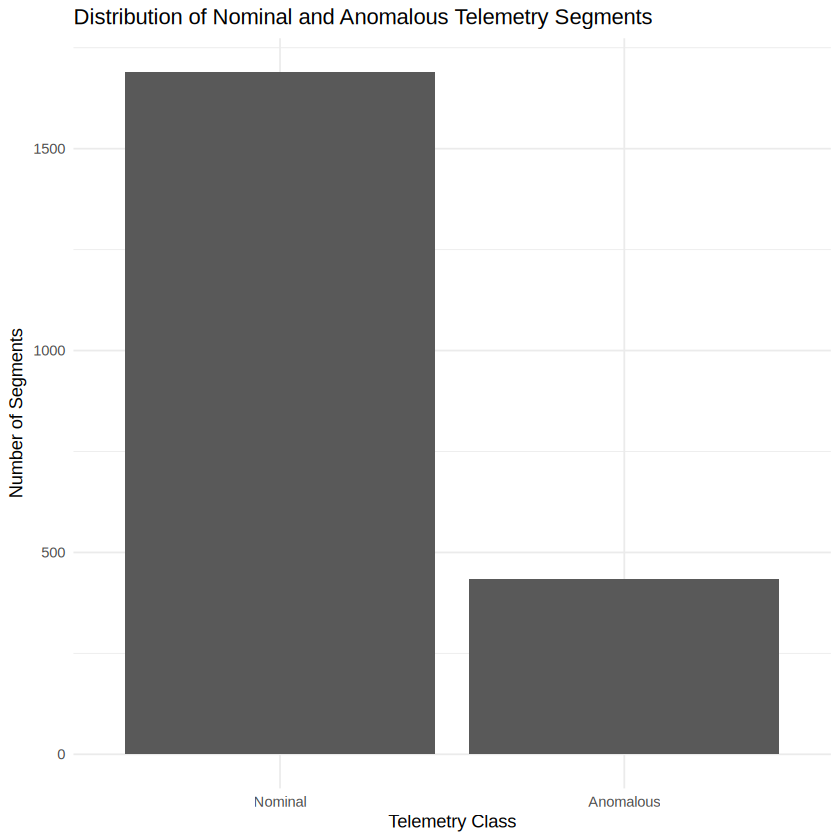

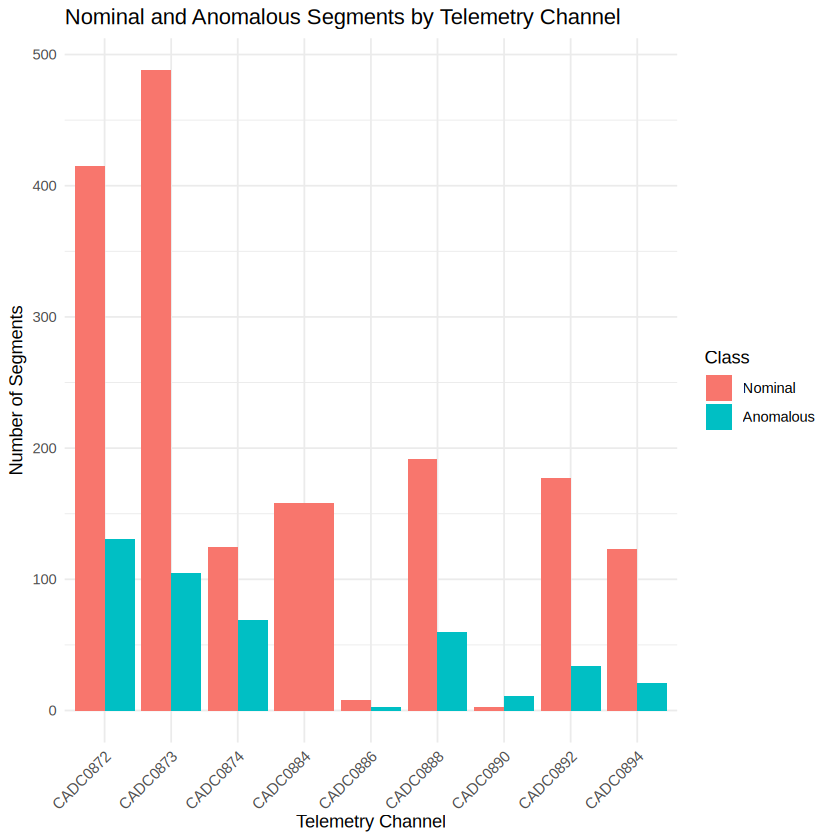

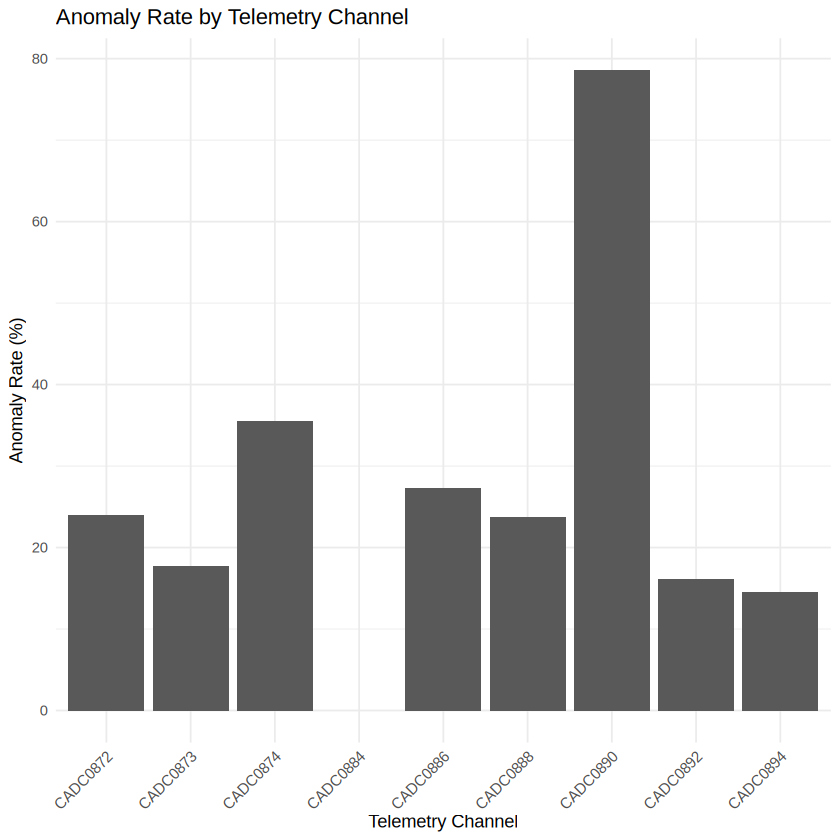

In [6]:
# Plot 1: overall class distribution
p1 <- ggplot(data, aes(x = anomaly)) +
  geom_bar() +
  labs(
    title = "Distribution of Nominal and Anomalous Telemetry Segments",
    x = "Telemetry Class",
    y = "Number of Segments"
  ) +
  theme_minimal()
print(p1)
ggsave("/content/anomaly_distribution.png", p1, width = 7, height = 5, dpi = 300)

# Plot 2: anomaly counts by channel
channel_counts <- data %>%
  count(channel, anomaly)

p2 <- ggplot(channel_counts, aes(x = channel, y = n, fill = anomaly)) +
  geom_col(position = "dodge") +
  labs(
    title = "Nominal and Anomalous Segments by Telemetry Channel",
    x = "Telemetry Channel",
    y = "Number of Segments",
    fill = "Class"
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
print(p2)
ggsave("/content/channel_class_counts.png", p2, width = 9, height = 5.5, dpi = 300)

# Plot 3: anomaly rate by channel
channel_rate <- data %>%
  group_by(channel) %>%
  summarise(
    total = n(),
    anomalies = sum(anomaly == "Anomalous"),
    anomaly_rate = anomalies / total * 100,
    .groups = "drop"
  )

p3 <- ggplot(channel_rate, aes(x = channel, y = anomaly_rate)) +
  geom_col() +
  labs(
    title = "Anomaly Rate by Telemetry Channel",
    x = "Telemetry Channel",
    y = "Anomaly Rate (%)"
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
print(p3)
ggsave("/content/anomaly_rate_by_channel.png", p3, width = 9, height = 5.5, dpi = 300)

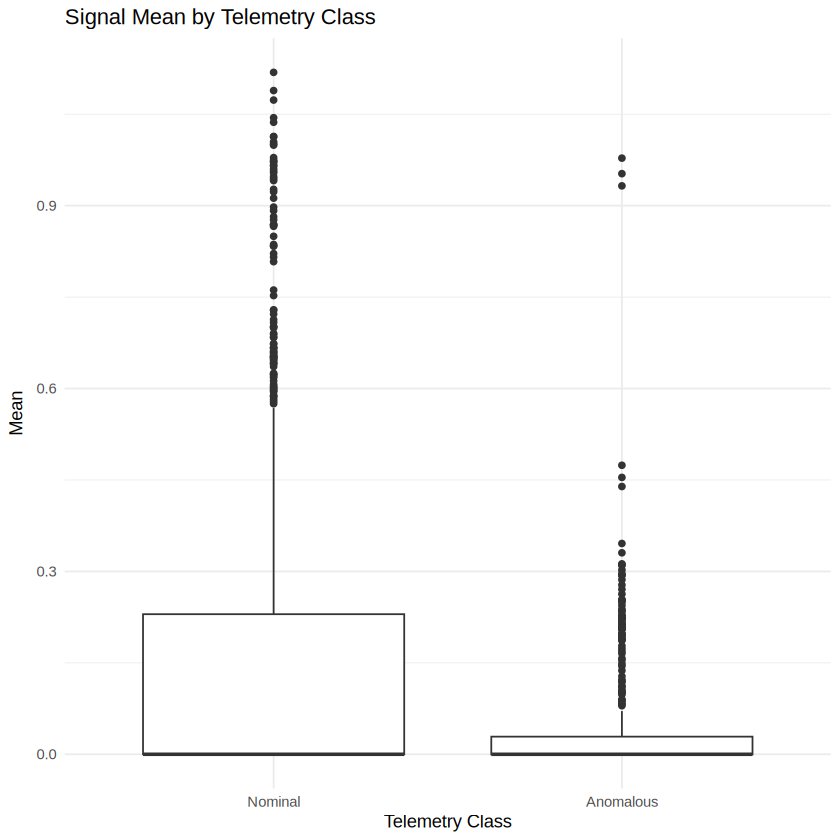



Table: Summary of Selected Telemetry Features by Class

|anomaly   | segments| mean_signal_mean| median_std| median_var|
|:---------|--------:|----------------:|----------:|----------:|
|Nominal   |     1689|           0.1271|          0|          0|
|Anomalous |      434|           0.0483|          0|          0|

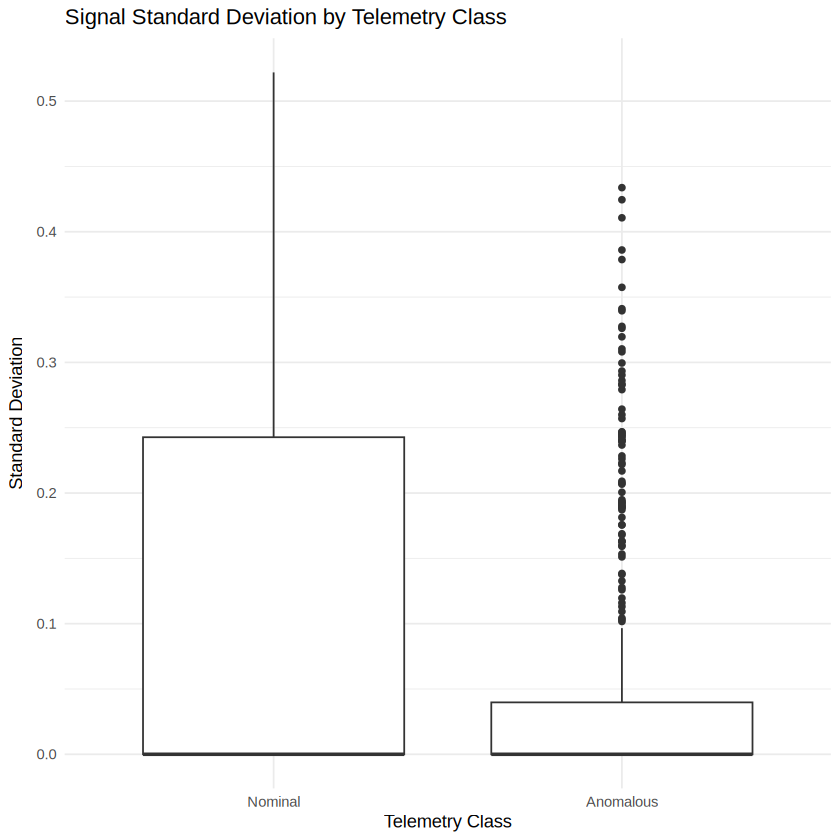

In [7]:
# Feature distribution: mean
p4 <- ggplot(data, aes(x = anomaly, y = mean)) +
  geom_boxplot() +
  labs(
    title = "Signal Mean by Telemetry Class",
    x = "Telemetry Class",
    y = "Mean"
  ) +
  theme_minimal()
print(p4)
ggsave("/content/mean_by_class.png", p4, width = 7, height = 5, dpi = 300)

# Feature distribution: standard deviation
p5 <- ggplot(data, aes(x = anomaly, y = std)) +
  geom_boxplot() +
  labs(
    title = "Signal Standard Deviation by Telemetry Class",
    x = "Telemetry Class",
    y = "Standard Deviation"
  ) +
  theme_minimal()
print(p5)
ggsave("/content/std_by_class.png", p5, width = 7, height = 5, dpi = 300)

# Summary table by class
class_summary <- data %>%
  group_by(anomaly) %>%
  summarise(
    segments = n(),
    mean_signal_mean = mean(mean, na.rm = TRUE),
    median_std = median(std, na.rm = TRUE),
    median_var = median(var, na.rm = TRUE),
    .groups = "drop"
  )

kable(class_summary, digits = 4, caption = "Summary of Selected Telemetry Features by Class")

## 7. Model preparation

The official `train` flag is used to preserve the benchmark split. `segment` is an identifier and `train` is a split indicator, so neither is passed to the models.

In [8]:
model_formula <- as.formula(
  paste("anomaly ~", paste(predictor_cols, collapse = " + "))
)

cat("Model formula:
")
print(model_formula)

Model formula:
anomaly ~ channel + sampling + duration + len + mean + var + 
    std + kurtosis + skew + n_peaks + smooth10_n_peaks + smooth20_n_peaks + 
    diff_peaks + diff2_peaks + diff_var + diff2_var + gaps_squared + 
    len_weighted + var_div_duration + var_div_len


## 8. Random Forest model

Random Forest is used as the primary model because it can capture nonlinear relationships among telemetry features and provides feature-importance measures.

In [9]:
rf_model <- randomForest(
  formula = model_formula,
  data = train_data,
  ntree = 500,
  importance = TRUE,
  na.action = na.omit
)

print(rf_model)


Call:
 randomForest(formula = model_formula, data = train_data, ntree = 500,      importance = TRUE, na.action = na.omit) 
               Type of random forest: classification
                     Number of trees: 500
No. of variables tried at each split: 4

        OOB estimate of  error rate: 3.95%
Confusion matrix:
          Nominal Anomalous class.error
Nominal      1259        14  0.01099764
Anomalous      49       272  0.15264798


## 9. Logistic Regression comparison model

Logistic Regression is included as an interpretable linear baseline. Comparing it with Random Forest shows whether nonlinear relationships add useful predictive power.

In [10]:
lr_model <- glm(
  model_formula,
  data = train_data,
  family = binomial(link = "logit")
)

summary(lr_model)

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”



Call:
glm(formula = model_formula, family = binomial(link = "logit"), 
    data = train_data)

Coefficients:
                   Estimate Std. Error z value Pr(>|z|)    
(Intercept)      -2.775e+00  1.214e+00  -2.286 0.022259 *  
channelCADC0873  -1.258e+00  3.579e-01  -3.517 0.000437 ***
channelCADC0874  -1.184e+00  7.004e-01  -1.691 0.090864 .  
channelCADC0884  -1.531e+01  7.849e+02  -0.020 0.984438    
channelCADC0886   4.420e+00  1.978e+00   2.235 0.025442 *  
channelCADC0888   3.310e+00  1.042e+00   3.177 0.001486 ** 
channelCADC0890  -1.404e+01  1.115e+03  -0.013 0.989958    
channelCADC0892   3.671e+00  1.039e+00   3.533 0.000412 ***
channelCADC0894  -6.477e-01  1.283e+00  -0.505 0.613796    
sampling         -7.880e-01  1.932e-01  -4.079 4.52e-05 ***
duration         -8.227e-02  2.576e-02  -3.194 0.001403 ** 
len               9.896e-02  2.588e-02   3.823 0.000132 ***
mean             -1.867e+00  3.072e+00  -0.608 0.543276    
var               3.590e+01  2.540e+01   1.414 0.1

## 10. Predictions

In [11]:
rf_class <- predict(rf_model, newdata = test_data, type = "class")
rf_prob  <- predict(rf_model, newdata = test_data, type = "prob")[, "Anomalous"]

lr_prob <- predict(lr_model, newdata = test_data, type = "response")
lr_class <- factor(ifelse(lr_prob >= 0.5, "Anomalous", "Nominal"),
                   levels = levels(test_data$anomaly))

cat("Random Forest predictions:
")
print(head(rf_class))
cat("
Logistic Regression predictions:
")
print(head(lr_class))

Random Forest predictions:
        5         7        12        13        18        20 
  Nominal   Nominal   Nominal Anomalous   Nominal Anomalous 
Levels: Nominal Anomalous

Logistic Regression predictions:
        5         7        12        13        18        20 
  Nominal   Nominal   Nominal Anomalous   Nominal Anomalous 
Levels: Nominal Anomalous


## 11. Evaluation metrics

The official OPSSAT-AD paper evaluates models using Accuracy, Precision, Recall, F1, MCC, ROC-AUC and PR-AUC. The following functions calculate the same metric family for our R models.

In [14]:
classification_metrics <- function(actual, predicted) {
  actual <- factor(actual, levels = c("Nominal", "Anomalous"))
  predicted <- factor(predicted, levels = c("Nominal", "Anomalous"))
  cm <- table(Actual = actual, Predicted = predicted)

  TN <- cm["Nominal", "Nominal"]
  FP <- cm["Nominal", "Anomalous"]
  FN <- cm["Anomalous", "Nominal"]
  TP <- cm["Anomalous", "Anomalous"]

  precision <- ifelse(TP + FP == 0, 0, TP / (TP + FP))
  recall <- ifelse(TP + FN == 0, 0, TP / (TP + FN))
  accuracy <- (TP + TN) / sum(cm)
  f1 <- ifelse(precision + recall == 0, 0, 2 * precision * recall / (precision + recall))
  mcc_den <- sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN))
  mcc <- ifelse(mcc_den == 0, 0, ((TP * TN) - (FP * FN)) / mcc_den)

  list(
    confusion = cm,
    accuracy = accuracy,
    precision = precision,
    recall = recall,
    f1 = f1,
    mcc = mcc,
    specificity = ifelse(TN + FP == 0, 0, TN / (TN + FP))
  )
}

pr_auc_value <- function(actual, probabilities) {
  actual_binary <- ifelse(actual == "Anomalous", 1, 0)
  pr_obj <- PRROC::pr.curve(
    scores.class0 = probabilities[actual_binary == 1],
    scores.class1 = probabilities[actual_binary == 0],
    curve = TRUE
  )
  as.numeric(pr_obj$auc.integral)
}

roc_auc_value <- function(actual, probabilities) {
  roc_obj <- pROC::roc(
    response = actual,
    predictor = probabilities,
    levels = c("Nominal", "Anomalous"),
    direction = "<",
    quiet = TRUE
  )
  as.numeric(pROC::auc(roc_obj))
}

rf_metrics <- classification_metrics(test_data$anomaly, rf_class)
rf_roc_auc <- roc_auc_value(test_data$anomaly, rf_prob)
rf_pr_auc <- pr_auc_value(test_data$anomaly, rf_prob)

lr_metrics <- classification_metrics(test_data$anomaly, lr_class)
lr_roc_auc <- roc_auc_value(test_data$anomaly, lr_prob)
lr_pr_auc <- pr_auc_value(test_data$anomaly, lr_prob)

metrics_summary <- data.frame(
  Model = c("Random Forest", "Logistic Regression"),
  Accuracy = c(rf_metrics$accuracy, lr_metrics$accuracy),
  Precision = c(rf_metrics$precision, lr_metrics$precision),
  Recall = c(rf_metrics$recall, lr_metrics$recall),
  F1 = c(rf_metrics$f1, lr_metrics$f1),
  MCC = c(rf_metrics$mcc, lr_metrics$mcc),
  ROC_AUC = c(rf_roc_auc, lr_roc_auc),
  PR_AUC = c(rf_pr_auc, lr_pr_auc)
)

# Round only the numeric columns for printing
metrics_summary_rounded <- metrics_summary
numeric_cols <- sapply(metrics_summary_rounded, is.numeric)
metrics_summary_rounded[numeric_cols] <- round(metrics_summary_rounded[numeric_cols], 4)

print(metrics_summary_rounded)
write.csv(metrics_summary, "/content/metrics_summary.csv", row.names = FALSE)

                Model Accuracy Precision Recall     F1   MCC ROC_AUC PR_AUC
1       Random Forest   0.9660    0.9524 0.8850 0.9174 0.897  0.9914 0.9747
2 Logistic Regression   0.9641    0.9700 0.8584 0.9108 0.891  0.9743 0.9489


## 12. Confusion matrices

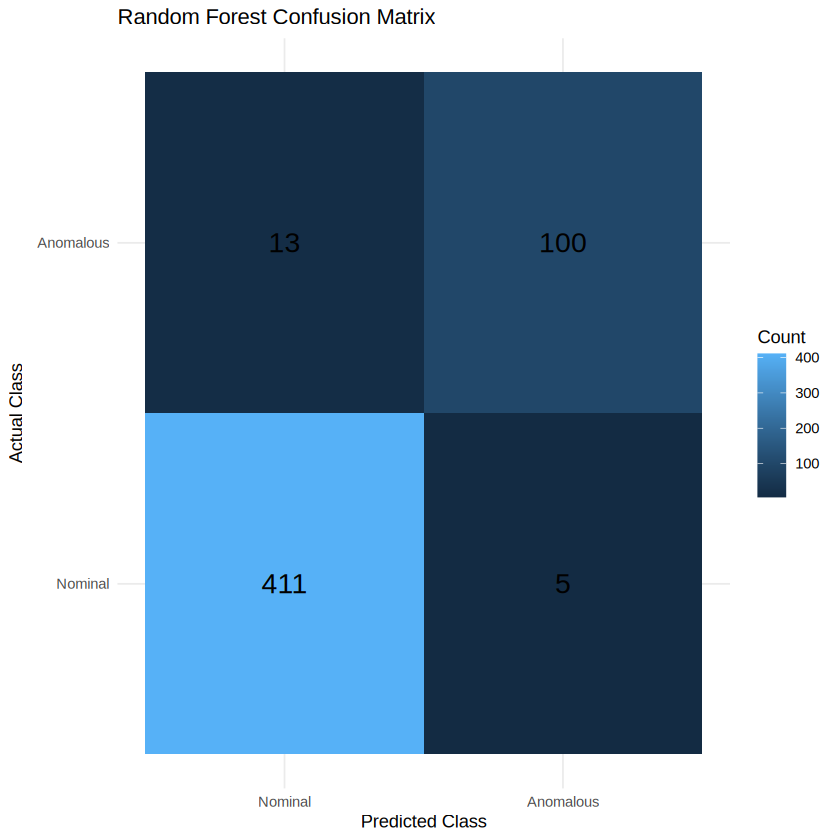

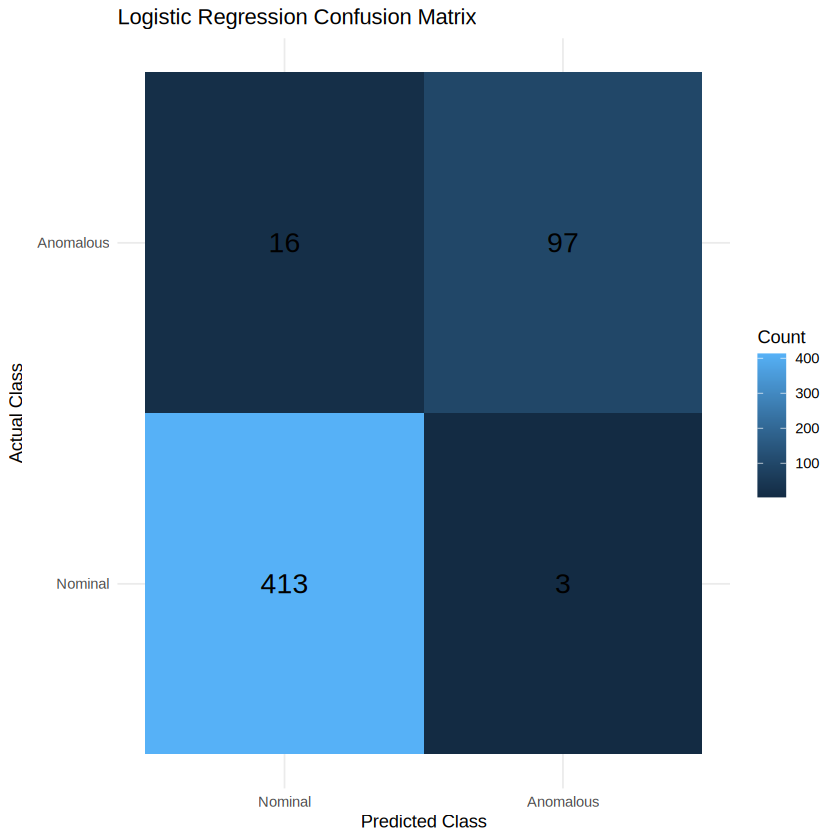

In [15]:
plot_confusion_matrix <- function(cm, title_text) {
  cm_df <- as.data.frame(cm)
  names(cm_df) <- c("Actual", "Predicted", "Count")

  ggplot(cm_df, aes(x = Predicted, y = Actual, fill = Count)) +
    geom_tile() +
    geom_text(aes(label = Count), size = 6) +
    labs(title = title_text, x = "Predicted Class", y = "Actual Class") +
    theme_minimal()
}

rf_cm_plot <- plot_confusion_matrix(rf_metrics$confusion, "Random Forest Confusion Matrix")
print(rf_cm_plot)
ggsave("/content/random_forest_confusion_matrix.png", rf_cm_plot, width = 7, height = 5.5, dpi = 300)

lr_cm_plot <- plot_confusion_matrix(lr_metrics$confusion, "Logistic Regression Confusion Matrix")
print(lr_cm_plot)
ggsave("/content/logistic_regression_confusion_matrix.png", lr_cm_plot, width = 7, height = 5.5, dpi = 300)

## 13. ROC and Precision-Recall curves

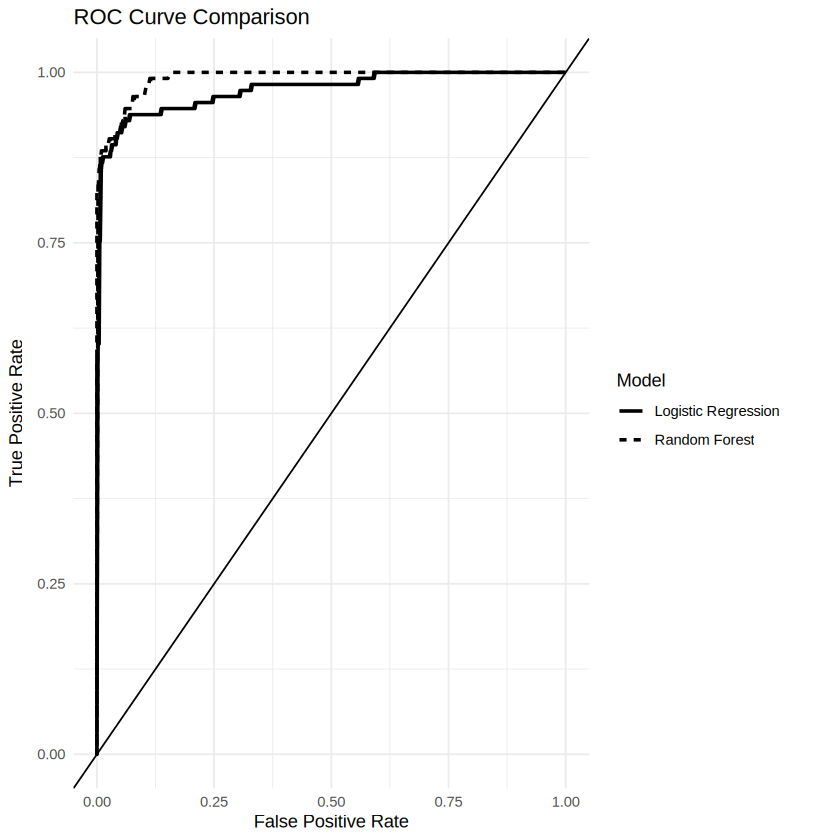

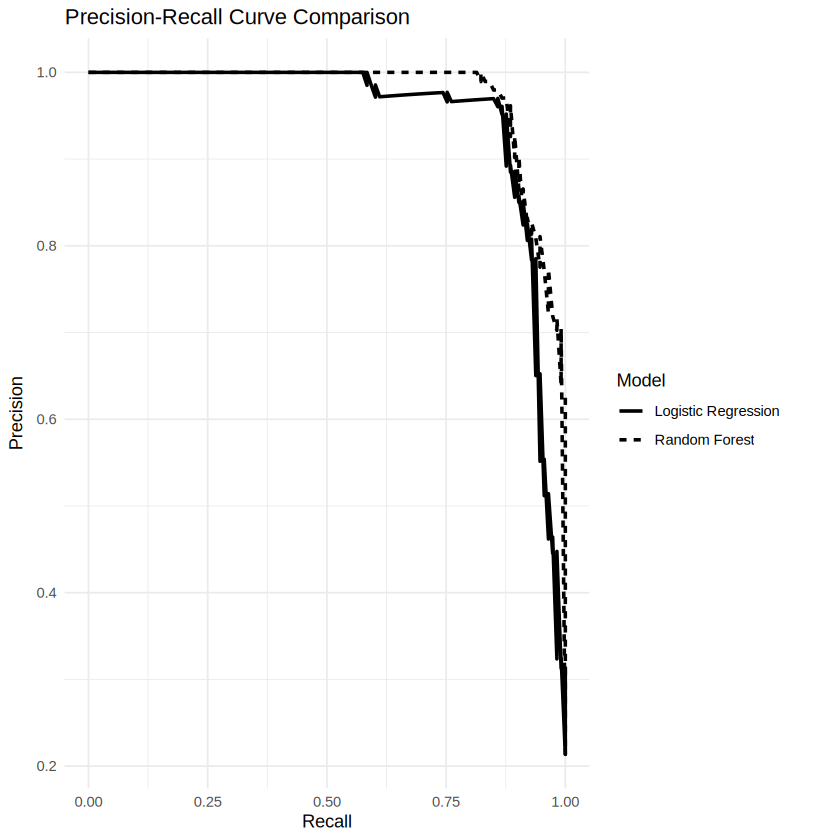

In [16]:
roc_rf <- pROC::roc(test_data$anomaly, rf_prob,
                    levels = c("Nominal", "Anomalous"),
                    direction = "<", quiet = TRUE)
roc_lr <- pROC::roc(test_data$anomaly, lr_prob,
                    levels = c("Nominal", "Anomalous"),
                    direction = "<", quiet = TRUE)

roc_df_rf <- data.frame(
  FPR = 1 - roc_rf$specificities,
  TPR = roc_rf$sensitivities,
  Model = "Random Forest"
)
roc_df_lr <- data.frame(
  FPR = 1 - roc_lr$specificities,
  TPR = roc_lr$sensitivities,
  Model = "Logistic Regression"
)
roc_df <- rbind(roc_df_rf, roc_df_lr)

p6 <- ggplot(roc_df, aes(x = FPR, y = TPR, linetype = Model)) +
  geom_line(linewidth = 1) +
  geom_abline(slope = 1, intercept = 0) +
  labs(
    title = "ROC Curve Comparison",
    x = "False Positive Rate",
    y = "True Positive Rate"
  ) +
  theme_minimal()
print(p6)
ggsave("/content/roc_comparison.png", p6, width = 7, height = 5.5, dpi = 300)

pr_rf <- PRROC::pr.curve(
  scores.class0 = rf_prob[test_data$anomaly == "Anomalous"],
  scores.class1 = rf_prob[test_data$anomaly == "Nominal"],
  curve = TRUE
)
pr_lr <- PRROC::pr.curve(
  scores.class0 = lr_prob[test_data$anomaly == "Anomalous"],
  scores.class1 = lr_prob[test_data$anomaly == "Nominal"],
  curve = TRUE
)

pr_df_rf <- data.frame(
  Recall = pr_rf$curve[, 1],
  Precision = pr_rf$curve[, 2],
  Model = "Random Forest"
)
pr_df_lr <- data.frame(
  Recall = pr_lr$curve[, 1],
  Precision = pr_lr$curve[, 2],
  Model = "Logistic Regression"
)
pr_df <- rbind(pr_df_rf, pr_df_lr)

p7 <- ggplot(pr_df, aes(x = Recall, y = Precision, linetype = Model)) +
  geom_line(linewidth = 1) +
  labs(
    title = "Precision-Recall Curve Comparison",
    x = "Recall",
    y = "Precision"
  ) +
  theme_minimal()
print(p7)
ggsave("/content/pr_comparison.png", p7, width = 7, height = 5.5, dpi = 300)

## 14. Random Forest feature importance

Feature importance helps identify which telemetry characteristics contributed most to the Random Forest's classification decisions.

            Feature Importance
1           n_peaks  104.51889
2  smooth10_n_peaks   55.07902
3       diff2_peaks   42.90852
4         diff2_var   40.55061
5        diff_peaks   37.71309
6       var_div_len   29.70061
7          kurtosis   20.85096
8               len   20.17019
9          diff_var   19.00032
10     gaps_squared   18.96970


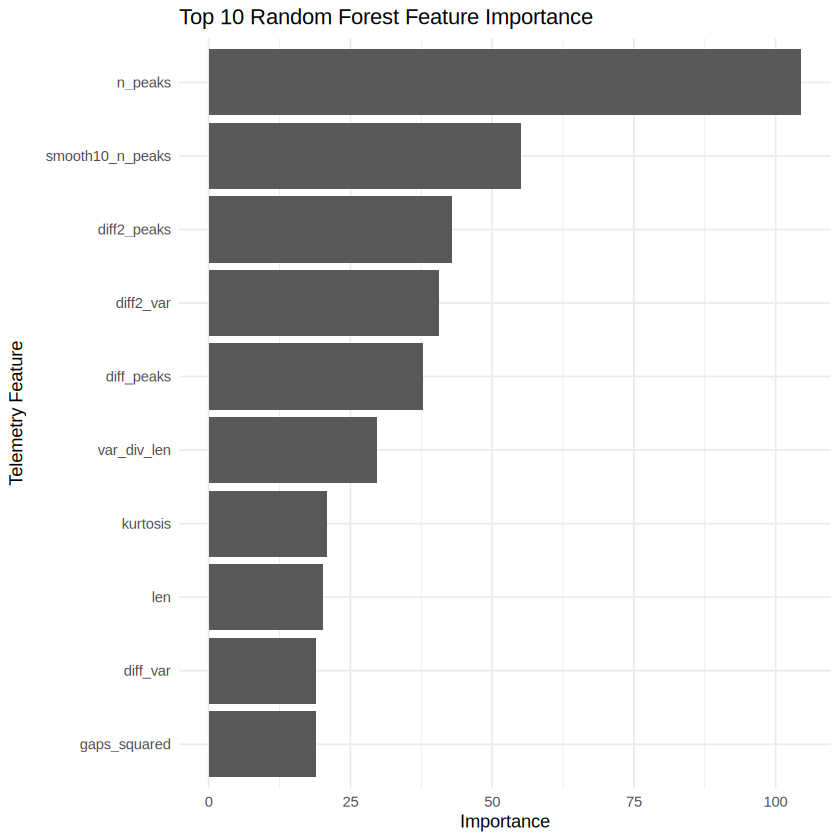

In [17]:
importance_values <- importance(rf_model, type = 2)
importance_df <- data.frame(
  Feature = rownames(importance_values),
  Importance = importance_values[, 1],
  row.names = NULL
) %>%
  arrange(desc(Importance))

print(head(importance_df, 10))
write.csv(importance_df, "/content/random_forest_feature_importance.csv", row.names = FALSE)

p8 <- importance_df %>%
  slice_head(n = 10) %>%
  mutate(Feature = reorder(Feature, Importance)) %>%
  ggplot(aes(x = Feature, y = Importance)) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Top 10 Random Forest Feature Importance",
    x = "Telemetry Feature",
    y = "Importance"
  ) +
  theme_minimal()
print(p8)
ggsave("/content/random_forest_feature_importance.png", p8, width = 8, height = 5.5, dpi = 300)

## 15. Final model selection and interpretation

For this case study, the **Random Forest** is selected as the final model when it provides the stronger overall combination of **F1 and PR-AUC** on the official test split. The exact values below are calculated from the current R run and are not manually entered.

In [18]:
best_model <- metrics_summary %>%
  arrange(desc(F1), desc(PR_AUC)) %>%
  slice(1)

cat("Selected final model based on F1 and PR-AUC:
")
print(best_model)

cat("
Random Forest confusion matrix:
")
print(rf_metrics$confusion)

cat("
Random Forest metric interpretation:
")
cat(sprintf("Accuracy: %.4f
", rf_metrics$accuracy))
cat(sprintf("Precision: %.4f
", rf_metrics$precision))
cat(sprintf("Recall: %.4f
", rf_metrics$recall))
cat(sprintf("F1-score: %.4f
", rf_metrics$f1))
cat(sprintf("MCC: %.4f
", rf_metrics$mcc))
cat(sprintf("ROC-AUC: %.4f
", rf_roc_auc))
cat(sprintf("PR-AUC: %.4f
", rf_pr_auc))

Selected final model based on F1 and PR-AUC:
          Model  Accuracy Precision    Recall        F1      MCC   ROC_AUC
1 Random Forest 0.9659735  0.952381 0.8849558 0.9174312 0.896997 0.9914164
     PR_AUC
1 0.9747479

Random Forest confusion matrix:
           Predicted
Actual      Nominal Anomalous
  Nominal       411         5
  Anomalous      13       100

Random Forest metric interpretation:
Accuracy: 0.9660
Precision: 0.9524
Recall: 0.8850
F1-score: 0.9174
MCC: 0.8970
ROC-AUC: 0.9914
PR-AUC: 0.9747


## 16. Save final outputs

The generated tables, plots, and metric files are saved in `/content/` for easy download from the Colab file browser.

In [19]:
output_files <- c(
  "/content/metrics_summary.csv",
  "/content/random_forest_feature_importance.csv",
  "/content/anomaly_distribution.png",
  "/content/channel_class_counts.png",
  "/content/anomaly_rate_by_channel.png",
  "/content/mean_by_class.png",
  "/content/std_by_class.png",
  "/content/random_forest_confusion_matrix.png",
  "/content/logistic_regression_confusion_matrix.png",
  "/content/roc_comparison.png",
  "/content/pr_comparison.png",
  "/content/random_forest_feature_importance.png"
)

existing_outputs <- output_files[file.exists(output_files)]
print(existing_outputs)

zip::zip(
  zipfile = "/content/Satellite_Telemetry_Results.zip",
  files = existing_outputs,
  mode = "cherry-pick"
)

cat("Created /content/Satellite_Telemetry_Results.zip
")

 [1] "/content/metrics_summary.csv"                     
 [2] "/content/random_forest_feature_importance.csv"    
 [3] "/content/anomaly_distribution.png"                
 [4] "/content/channel_class_counts.png"                
 [5] "/content/anomaly_rate_by_channel.png"             
 [6] "/content/mean_by_class.png"                       
 [7] "/content/std_by_class.png"                        
 [8] "/content/random_forest_confusion_matrix.png"      
 [9] "/content/logistic_regression_confusion_matrix.png"
[10] "/content/roc_comparison.png"                      
[11] "/content/pr_comparison.png"                       
[12] "/content/random_forest_feature_importance.png"    
Created /content/Satellite_Telemetry_Results.zip


## 17. Coursework conclusion

**Conclusion template generated from the actual run:**

The study analyzed the official OPSSAT-AD satellite telemetry dataset and used the benchmark's train/test split. Data-quality checks, preprocessing, exploratory analysis and visualization were completed in R. Random Forest and Logistic Regression were evaluated as supervised binary classifiers for identifying anomalous telemetry segments. The final model should be discussed using precision, recall, F1-score, MCC, ROC-AUC and PR-AUC, with particular attention to the anomaly class because anomalies are less frequent than nominal observations.

Use the actual metric values printed above in your final report and PPT. Do not manually replace them with published benchmark values. Published OPSSAT-AD results may be included only as a separate reference comparison.